# MoG40: a 40-mode Gaussian mixture (2-D)

The target is the equal-weight mixture of 40 unit-covariance Gaussians from Midgley et al. (2023),

$$\pi(x)=\frac1{40}\sum_{i=1}^{40}\mathcal N(x;\,\mu_i,\,I),\qquad
\mu_i\sim\mathcal U\big([-40,40]^2\big),$$

with the means fixed by one seed. The modes are well separated.

Each method fits a mixture of $K=40$ components for 300 iterations from a shared
initialisation. The settings are in `configs/MoG40/base.toml`.

In [1]:
%matplotlib inline
# Figures are embedded in the notebook as PNG (displayed) and vector PDF; none is written to disk.
%config InlineBackend.figure_formats = ["png", "pdf"]
import os
# Pin the kernel to ONE physical GPU BEFORE importing JAX (indices change between sessions --
# re-check `nvidia-smi` and pick an idle card).
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1")
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from gmmvi import benchmark, metrics, plotting

GROUP   = "MoG40"                        # configs/MoG40/base.toml <-> results/MoG40.npz
CFG     = benchmark.load_config(GROUP)

## 1. The target

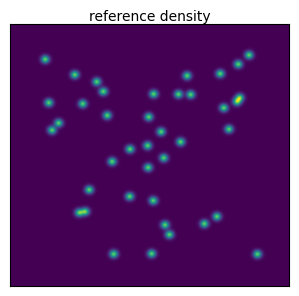

In [2]:
from gmmvi.targets import registry

spec = registry.build(CFG.get("target", GROUP))
DIM  = spec.dim

plotting.density_panel(spec, reference=True, figsize=(3.6, 3.4), title="reference density")
plt.show()

## 2. The saved run

In [3]:
RESULTS = benchmark.require_results(GROUP)
SEEDS   = sorted({s for _, s in RESULTS})
METHODS = [m for m in ["gmbbvi", "semtrux", "ibw", "WFR"] if any(k[0] == m for k in RESULTS)]
GROUPED = benchmark.group_seeds(RESULTS, METHODS)

SPREAD       = "std"
SPREAD_LABEL = rf"mean $\pm$ 1 s.d. over {len(SEEDS)} seeds"
SEED    = SEEDS[0]
RES     = {m: GROUPED[m][SEED] for m in METHODS}
K, N_ITER = RES[METHODS[0]].K, RES[METHODS[0]].n_iterations
m0      = RES[METHODS[0]].means_log[0]

## 3. The shared initialisation

Every method starts from the same mixture. The means are drawn from $\mathcal N(0,\,40^2 I)$, so
they spread over the whole mode grid, and the covariances are $10^{-5}I$.

init means:       ||m_k|| in [7.7, 107.8]
init covariances: 1e-05 * I


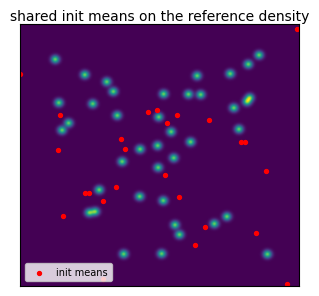

In [4]:
_init = benchmark.make_init(CFG, spec, SEED)
assert np.array_equal(_init.means.astype(m0.dtype), m0), \
    "the config's init does not reproduce the stored means"
assert np.allclose(_init.covariances, _init.covariances[0, 0, 0] * np.eye(DIM))
for m in METHODS:
    assert np.allclose(RES[m].means_log[0], m0), f"{m} started from a different init?"
    assert np.allclose(RES[m].covs_log[0], _init.covariances, rtol=1e-6, atol=0), m
print("init means:       ||m_k|| in [%.1f, %.1f]"
      % (np.linalg.norm(m0, axis=1).min(), np.linalg.norm(m0, axis=1).max()))
print("init covariances: %.0e * I" % _init.covariances[0, 0, 0])

ax = plotting.density_panel(spec, reference=True, figsize=(3.6, 3.4),
                            title="shared init means on the reference density")
ax.scatter(m0[:, 0], m0[:, 1], s=8, c="red", label="init means")
ax.legend(fontsize=7, loc="lower left")
plt.show()

## 5. Fitted densities

The reference density and each method's final mixture for seed `SEED`, with the TV to the
reference in each title. Black crosses mark the target modes, blue ellipses the fitted
components at $3\sigma$, and red the shared initialisation.
`SNAP_ITER` selects a logged snapshot instead of the final fit.

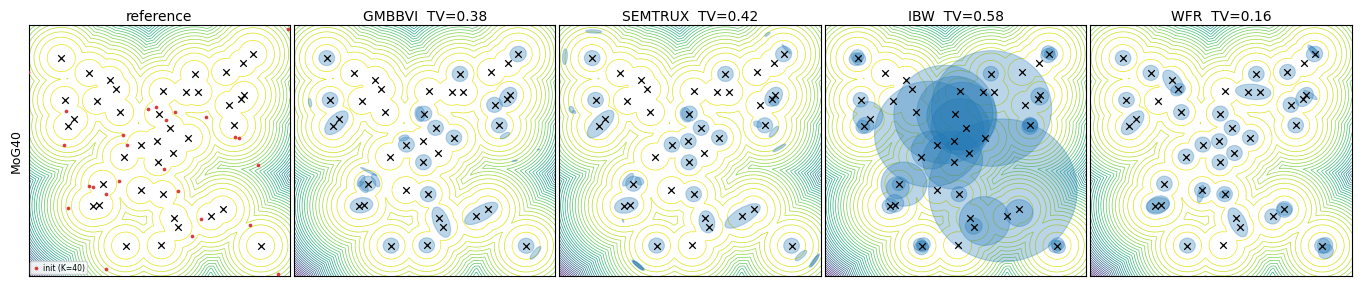

In [5]:
SNAP_ITER = None          # None -> final fit; else nearest logged iteration

_its = np.asarray(RES[METHODS[0]].iters)
_j = None if SNAP_ITER is None else int(np.argmin(np.abs(_its - SNAP_ITER)))

def _snapshot(r):
    if _j is None:
        return r.means, r.covariances, r.weights
    return r.means_log[_j], r.covs_log[_j], r.weights_log[_j]

TITLES = {}
for m in METHODS:
    mm, cc, ww = _snapshot(RES[m])
    tv = metrics.total_variation(spec.grid_pts, spec.ref_density, mm, cc, ww)
    TITLES[m] = f"{plotting.LABELS[m]}  TV={tv:.2f}"

_STYLE = dict(style="contour", n_sigma=3.0, levels=40)
_IKW   = dict(init_means=_init.means, init_covs=_init.covariances)
fig, axes = plotting.density_row(spec, RES, methods=METHODS, titles=TITLES, ylabel="MoG40",
                                 snapshot=_j, **_STYLE, **_IKW)
plt.show()

## 5b. Reverse KL on a shared evaluator

Every stored snapshot is scored with the same random numbers for all methods, so iteration 0
agrees across methods and later differences come from the fits.

In [6]:
KL_ITERS, KLS = benchmark.kl_traces(GROUPED, spec=spec, config=CFG)

for m in METHODS:
    Y    = KLS[m]
    mean = np.nanmean(np.where(np.isfinite(Y), Y, np.nan), axis=0)
    print(f"{plotting.LABELS[m]:8s}: -ELBO {mean[0]:9.4f} -> {mean[-1]:8.4f}   "
          f"[mean of {len(Y)} seeds]")

GMBBVI  : -ELBO  342.4563 ->   0.5106   [mean of 5 seeds]
SEMTRUX : -ELBO  342.4563 ->   0.5098   [mean of 5 seeds]
IBW     : -ELBO  342.4563 ->   2.9018   [mean of 5 seeds]
WFR     : -ELBO  342.4563 ->   0.2277   [mean of 5 seeds]


## 6. Summary metrics

TV is against the grid reference, and the $-\mathrm{ELBO}$ is the final value from section 5b.
EMC (Blessing et al. 2024) is the entropy of the samples' histogram over the 40 modes: 0 when
one mode holds every sample, 1 when all modes hold equal shares. Coverage counts the modes with
a component mean within distance 3. MMD and entropic $W_2$ are against exact target samples. The
ESS cannot see modes that $q$ misses.

MoG40  (K=40, 300 iterations, seeds [0, 1, 2, 3, 4])
method       tv  neg_elbo     emc     ess     mmd  entropic_w2  coverage  weight_entropy
----------------------------------------------------------------------------------------
GMBBVI   0.3933    0.5106  0.8723  0.2943  0.1060      12.8878        25          0.8277
SEMTRUX  0.3815    0.5098  0.8804  0.1333  0.0902      12.2399        25          0.8341
IBW      0.5710    2.9018  0.8470  0.0121  0.1367      15.4076        21          1.0000
WFR      0.2147    0.2277  0.9538  0.5348  0.0493       9.9616        34          0.9108


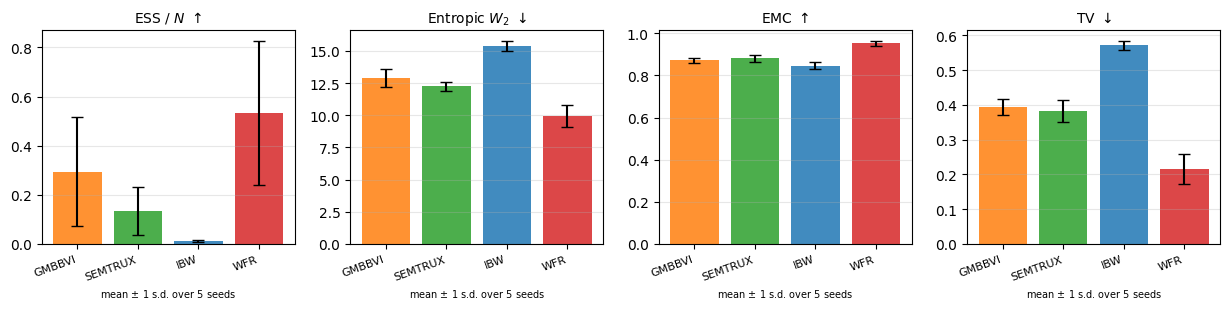

In [7]:
ROWS, TRACES = {}, {}
for m in METHODS:
    scored = {s: benchmark.evaluate(GROUPED[m][s], spec, CFG, traces=True)
              for s in sorted(GROUPED[m])}
    row = benchmark.evaluate_seeds(GROUPED[m], spec, CFG, spread=SPREAD, scores=scored)
    row.update(zip(("neg_elbo", "neg_elbo_std", "neg_elbo_n"),
                   benchmark.reduce_seeds(KLS[m][:, -1], SPREAD)))
    ROWS[m] = row
    TRACES[m] = {k: np.stack([np.asarray(scored[s][k], float) for s in sorted(scored)])
                 for k in ("tv_trace", "emc_trace", "ess_trace") if k in scored[SEED]}

print(f"MoG40  (K={K}, {N_ITER} iterations, seeds {SEEDS})")
print(plotting.summary_table(
    {m: {k: x for k, x in r.items() if not k.endswith("_std")} for m, r in ROWS.items()},
    columns=["tv", "neg_elbo", "emc", "ess", "mmd", "entropic_w2", "coverage",
             "weight_entropy"]))

plotting.metric_bars(ROWS, ["ess", "entropic_w2", "emc", "tv"], methods=METHODS,
                     spread_label=SPREAD_LABEL, figsize=(12.4, 3.2))
plt.tight_layout(); plt.show()

## 7. Convergence

The $-\mathrm{ELBO}$ from section 5b, TV, EMC and ESS against iteration, scored on the stored
snapshots every 10 iterations.

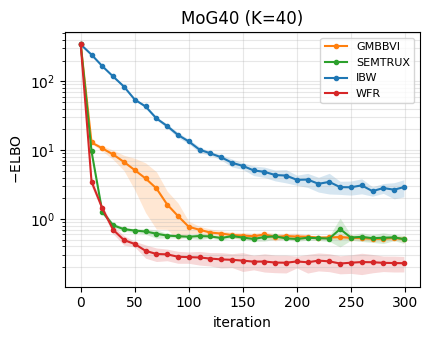

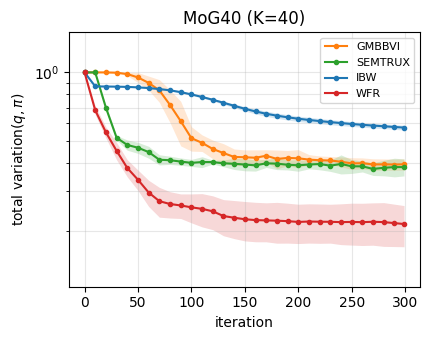

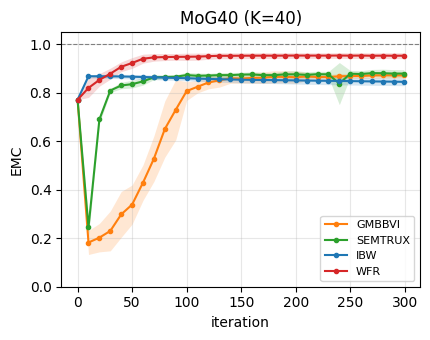

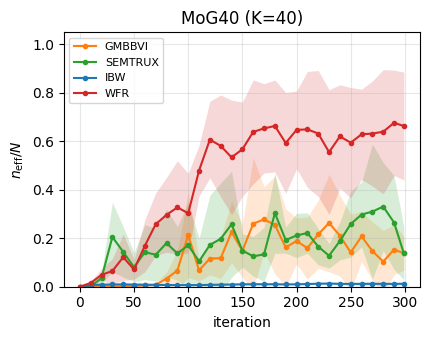

In [8]:
for key, ylabel, logy, ylim in [
    ("kls",       r"$-$ELBO",                              "auto", None),
    ("tv_trace",  r"total variation$(q,\pi)$",            "auto", None),
    ("emc_trace", "EMC",                                   False, (0, 1.05)),
    ("ess_trace", r"$n_{\rm eff}/N$",                     False, (0, 1.05)),
]:
    traces = {m: ((KL_ITERS, KLS[m]) if key == "kls"
                  else (RES[m].iters, TRACES[m][key])) for m in METHODS}
    fig, ax = plt.subplots(figsize=(4.4, 3.5))
    plotting.trace_panel(traces, ax=ax, ylabel=ylabel,
                         title=f"MoG40 (K={K})", logy=logy, spread=SPREAD)
    if ylim:
        ax.set_ylim(*ylim)
    if key == "emc_trace":
        ax.axhline(1.0, ls="--", lw=0.8, c="gray")
    plt.tight_layout(); plt.show()

## 7b. WFR with one branch only

The WFR run above, with the same steps but its W $\to$ FR gate replaced by a fixed schedule.
W-only takes the Wasserstein step for all 300 iterations; it never updates the weights, so they
stay uniform. FR-only takes the Fisher–Rao step from iteration 0. The runs are stored in
`results/MoG40/ablation_w_fr.npz`.

MoG40 base init, WFR ablation  (K=40, 300 iterations, seeds [0, 1, 2, 3, 4])
method       tv  neg_elbo  coverage     emc  weight_entropy     mmd  entropic_w2
--------------------------------------------------------------------------------
WFR      0.2147    0.2277        34  0.9538          0.9108  0.0493       9.9616
W-only   0.3713    0.5951        28  0.8801          1.0000  0.1447      15.2522
FR-only  0.3977    0.5151        24  0.8669          0.8245  0.1010      12.3052


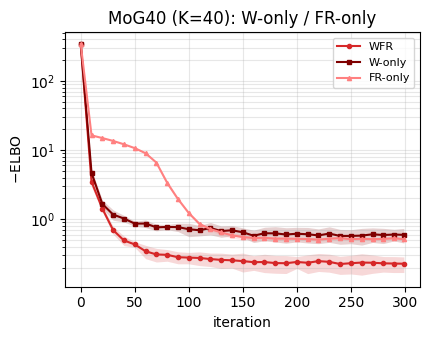

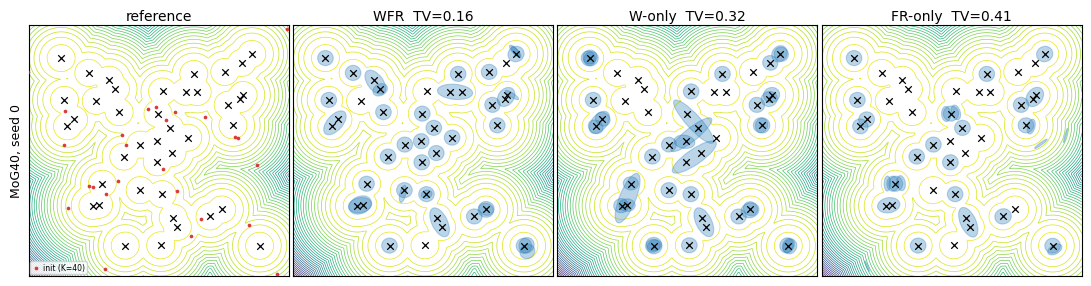

In [9]:
ABL_METHODS = ["WFR", "WFR_W_only", "WFR_FR_only"]
ABL_MARKER  = {"WFR": "-o", "WFR_W_only": "-s", "WFR_FR_only": "-^"}

ABL = dict(benchmark.group_seeds(benchmark.require_results("MoG40/ablation_w_fr"),
                                 ABL_METHODS[1:]))
ABL["WFR"] = GROUPED["WFR"]
_, ABL_KLS = benchmark.kl_traces({m: ABL[m] for m in ABL_METHODS[1:]}, spec=spec, config=CFG)
ABL_KLS["WFR"] = KLS["WFR"]

ABL_ROWS = {}
for m in ABL_METHODS:
    row = dict(ROWS["WFR"] if m == "WFR"
               else benchmark.evaluate_seeds(ABL[m], spec, CFG, spread=SPREAD))
    row.update(zip(("neg_elbo", "neg_elbo_std", "neg_elbo_n"),
                   benchmark.reduce_seeds(ABL_KLS[m][:, -1], SPREAD)))
    ABL_ROWS[plotting.LABELS[m]] = row

print(f"MoG40 base init, WFR ablation  (K={K}, {N_ITER} iterations, seeds {SEEDS})")
print(plotting.summary_table(
    {m: {k: x for k, x in r.items() if not k.endswith("_std")} for m, r in ABL_ROWS.items()},
    columns=["tv", "neg_elbo", "coverage", "emc", "weight_entropy", "mmd", "entropic_w2"]))

fig, ax = plt.subplots(figsize=(4.4, 3.5))
for m in ABL_METHODS:
    plotting.trace_panel({m: (KL_ITERS, ABL_KLS[m])}, ax=ax, ylabel=r"$-$ELBO", logy=True,
                         spread=SPREAD, marker=ABL_MARKER[m], legend=(m == ABL_METHODS[-1]))
ax.set_title(f"MoG40 (K={K}): W-only / FR-only")
plt.tight_layout(); plt.show()

_abl_res = {m: ABL[m][SEED] for m in ABL_METHODS}
_abl_titles = {m: f"{plotting.LABELS[m]}  TV={metrics.total_variation(spec.grid_pts, spec.ref_density, r.means, r.covariances, r.weights):.2f}"
               for m, r in _abl_res.items()}
fig, axes = plotting.density_row(spec, _abl_res, methods=ABL_METHODS, titles=_abl_titles,
                                 ylabel=f"MoG40, seed {SEED}", **_STYLE, **_IKW)
plt.show()

## 8. Init variants

The same comparison from three other starts, each with its own tuned steps: `init_standard`
(the base means with unit covariances), and `init_far` and `init_far_small_spread` (means around
$(30, 30)$, outside the mode grid, with spread 2 and 5). The settings are in
`configs/MoG40/init_*.toml`.

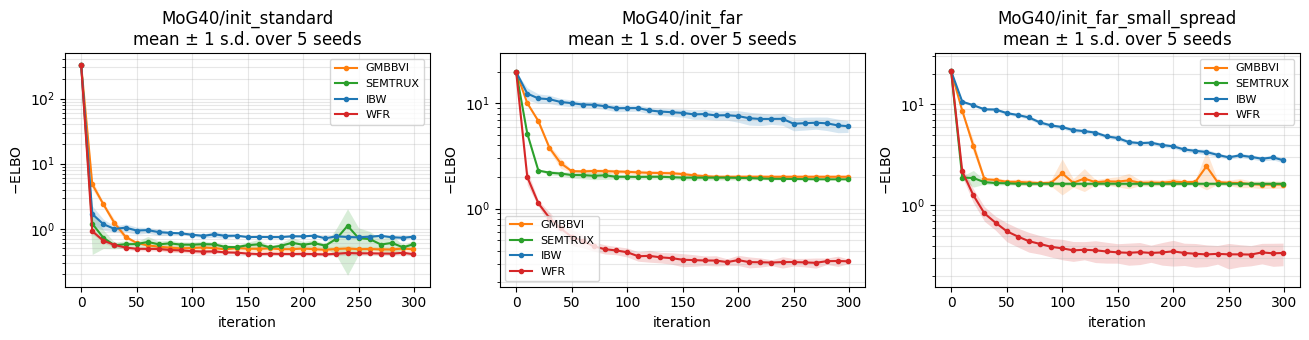

method                                   tv  neg_elbo  coverage
---------------------------------------------------------------
MoG40/init_standard:gmbbvi           0.3751    0.4822        26
MoG40/init_standard:semtrux          0.3830    0.5741        26
MoG40/init_standard:ibw              0.4466    0.7521        24
MoG40/init_standard:WFR              0.3348    0.4069        27
MoG40/init_far:gmbbvi                0.8642    2.0047         5
MoG40/init_far:semtrux               0.8500    1.8971         6
MoG40/init_far:ibw                   0.9234    6.0656         2
MoG40/init_far:WFR                   0.2687    0.3164        31
MoG40/init_far_small_spread:gmbbvi   0.7954    1.6092         8
MoG40/init_far_small_spread:semtrux  0.8050    1.6368         8
MoG40/init_far_small_spread:ibw      0.8500    2.8008         7
MoG40/init_far_small_spread:WFR      0.2809    0.3379        30


In [10]:
VARIANTS = ["MoG40/init_standard", "MoG40/init_far", "MoG40/init_far_small_spread"]
VRES = {v: benchmark.group_seeds(benchmark.require_results(v), METHODS) for v in VARIANTS}

VKLS = {}
fig, axes = plt.subplots(1, len(VRES), figsize=(4.4 * len(VRES), 3.5), squeeze=False)
for ax, (v, gr) in zip(axes[0], VRES.items()):
    _vi, VKLS[v] = benchmark.kl_traces(gr, spec=spec, config=CFG, verbose=False)
    n = min(len(runs) for runs in gr.values())
    plotting.trace_panel({m: (_vi, VKLS[v][m]) for m in VKLS[v]}, ax=ax, ylabel=r"$-$ELBO",
                         title=f"{v}\nmean $\\pm$ 1 s.d. over {n} seeds",
                         logy="auto", spread=SPREAD)
plt.tight_layout(); plt.show()

VROWS = {}
for v, gr in VRES.items():
    for m, runs in gr.items():
        tvs  = [metrics.total_variation(spec.grid_pts, spec.ref_density,
                                        r.means, r.covariances, r.weights)
                for r in runs.values()]
        covs = [metrics.mode_coverage(r.means, spec.mode_means, spec.mode_precisions)
                for r in runs.values()]
        row = {}
        for name, vals in (("tv", tvs), ("coverage", covs), ("neg_elbo", VKLS[v][m][:, -1])):
            row.update(zip((name, name + "_std", name + "_n"),
                           benchmark.reduce_seeds(vals, SPREAD)))
        VROWS[f"{v}:{m}"] = row
print(plotting.summary_table({m: {k: x for k, x in r.items() if not k.endswith("_std")} for m, r in VROWS.items()}, columns=["tv", "neg_elbo", "coverage"]))

### 8b. Fitted densities per init variant

The section-5 row for each variant at seed `SEED`, with that variant's initialisation in red.

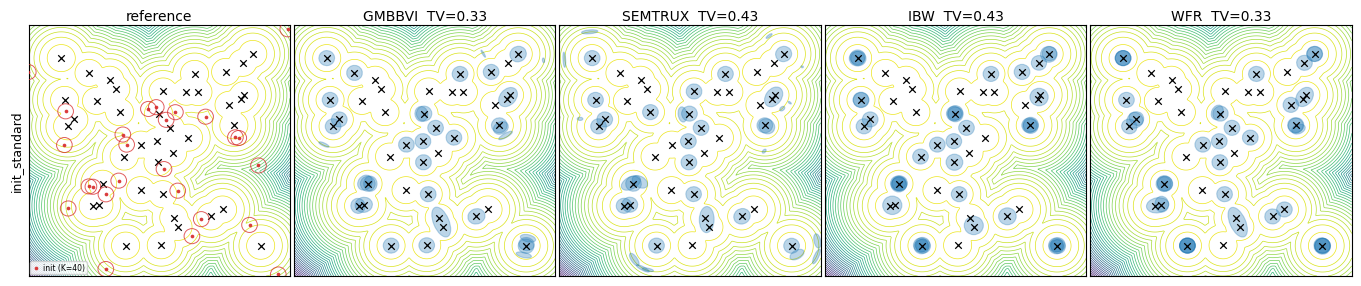

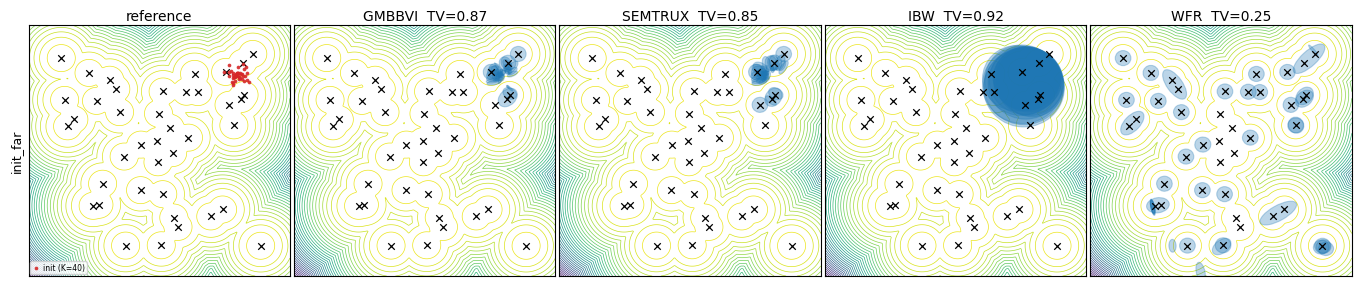

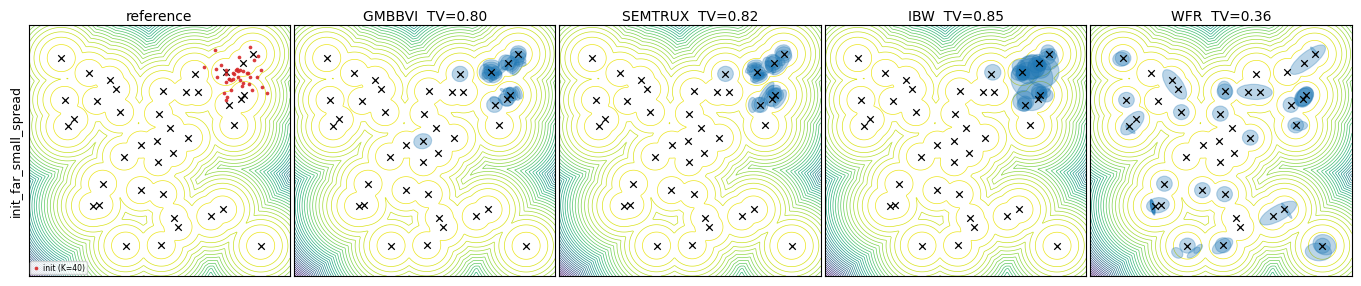

In [11]:
for v, gr in VRES.items():
    vres  = {m: gr[m][SEED] for m in METHODS}
    vinit = benchmark.make_init(benchmark.load_config(v), spec, SEED)
    _m0v  = vres[METHODS[0]].means_log[0]
    assert np.array_equal(vinit.means.astype(_m0v.dtype), _m0v), v
    vtitles = {}
    for m, r in vres.items():
        tv = metrics.total_variation(spec.grid_pts, spec.ref_density,
                                     r.means, r.covariances, r.weights)
        vtitles[m] = f"{plotting.LABELS[m]}  TV={tv:.2f}"
    fig, axes = plotting.density_row(spec, vres, methods=METHODS, titles=vtitles,
                                     ylabel=v.split("/")[-1], **_STYLE,
                                     init_means=vinit.means, init_covs=vinit.covariances)
    plt.show()